# SPY Return Prediction and Trading with XGBoost

Can eight market indicators forecast SPY's next five-session return and improve a
simple SPY/cash strategy? Fit XGBoost on SPY history, with two cross-market inputs
from QQQ and TLT. Compare prediction error with a training-sample historical mean
and trading performance with buy-and-hold and 20-session momentum.

This notebook contains the actual fixed-configuration fits for every development
fold, validation and historical evaluation. Each fit is checked against the saved
forecasts before calculating performance. Statistical inference is retrospective
and exploratory; historical evaluation is not a wholly unseen prospective test.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from xgboost import XGBRegressor
from methods import *

warnings.filterwarnings('ignore',message="The 'float_precision' argument is deprecated.*")
warnings.filterwarnings('ignore',message='Series.values returning an ndarray that drops timezone information.*')
verify_inputs()
spec=json.loads((ROOT/'model_spec.json').read_text())
assert spec['features']==FEATURES and len(FEATURES)==8
frames=load_prices()
assert set(frames)=={'SPY','QQQ','TLT'}
samples=make_samples(frames)
print('Daily ETF-price observations:',sum(d.adjclose.notna().sum() for d in frames.values()))
print('Eligible SPY origins:',len(samples))
display(pd.DataFrame({'ETF':list(frames),'observations':[d.adjclose.notna().sum() for d in frames.values()]}))

Daily ETF-price observations: 15093
Eligible SPY origins: 4985


,ETF,observations
0,SPY,5031
1,QQQ,5031
2,TLT,5031


## 1. Eight inputs and forecast timing

For each fund, $r_t=\log(C_t^{adj}/C_{t-1}^{adj})$. The eight inputs are
`SPY_r1`, `SPY_r2`, `SPY_r3`, `SPY_mom5`, `SPY_mom20`, `SPY_vol20`,
`QQQ_r1`, `TLT_r1`. Return lags are $r_t,r_{t-1},r_{t-2}$; momentum sums the
last five or twenty returns; volatility is the twenty-return sample standard
deviation (ddof=1). Features are decimal log returns; there is no feature selection.

At close $t$, predict
$$Y_t=100\log\left(\frac{O^{adj}_{t+6}}{O^{adj}_{t+1}}\right),
\qquad O_t^{adj}=O_t\frac{C_t^{adj}}{C_t}.$$
Entry is the next opening; the target ends five opening-to-opening intervals later.
No market prices are filled. Eligibility requires twenty complete feature rows
and observed SPY prices from $t-40$ through $t+6$. This availability mask is not
an additional input to XGBoost. Data use New York session dates and XNYS sessions.
Vendor-adjusted prices are revised historical total-return proxies, not guaranteed fills.

## 2. Expanding-window development and fixed settings

| Stage | Train through | Evaluate |
| --- | --- | --- |
| Development 1 | 2011 | 2012–2014 |
| Development 2 | 2014 | 2015–2017 |
| Development 3 | 2017 | 2018–2019 |
| Validation | 2019 | 2020–2021 |
| Historical evaluation | 2021 | 2022–2025 |

1. Build features from information available at the origin.
2. Sample training origins every fifth exchange session, on the March 2, 2006 phase.
3. Exclude labels not realized before the next stage begins.
4. Fit on training data and predict later eligible daily origins.
5. Refit through 2021 and keep the model fixed for 2022–2025.

Training targets do not overlap. Daily evaluation targets overlap, so inference
must allow serial dependence. The historical-mean benchmark uses the eligible
training targets and stays constant within each evaluation stage; its training
window expands between stages, not every day during evaluation.

Use 100 trees, depth 1, learning rate .03, minimum child weight 100 and L2 penalty
10, with the complete fixed settings below. No hyperparameter search is performed
in this notebook or inferred from these fixed settings.

In [2]:
display(spec['xgboost'])
stages=[(f'cv{i}',*dates) for i,dates in enumerate(spec['development_folds'],1)]
stages += [('validation',*spec['validation']),('test',*spec['test'])]
stage_forecasts={};size_rows=[];cv_rows=[]
for stage,train_end,start,end in stages:
    tr,ev=split_samples(samples,train_end,start,end)
    train=samples.loc[tr];evaluation=samples.loc[ev].sort_values('origin')
    assert train.exit.max()<evaluation.origin.min()
    session_locations=frames['SPY'].index.get_indexer(train.origin)
    assert np.all(np.diff(session_locations)==5)
    model=XGBRegressor(**spec['xgboost'])
    model.fit(train[FEATURES].to_numpy(dtype='float32'),train.actual.to_numpy(dtype='float32'))
    fitted=model.predict(evaluation[FEATURES].to_numpy(dtype='float32'))
    frozen=pd.read_csv(ROOT/'results'/f'{stage}_forecasts.csv',parse_dates=['origin','entry','exit'],float_precision='round_trip')
    wide=frozen.pivot(index='origin',columns='model',values='prediction').sort_index()
    np.testing.assert_array_equal(wide.index.to_numpy(),evaluation.origin.to_numpy())
    np.testing.assert_array_equal(fitted,wide.XGBoost.to_numpy())
    np.testing.assert_array_equal(np.repeat(train.actual.mean(),len(evaluation)),wide.Mean.to_numpy())
    y=frozen.loc[frozen.model.eq('XGBoost'),'actual'].to_numpy()
    np.testing.assert_array_equal(y,evaluation.actual.to_numpy())
    assert set(wide.columns)==set(MODELS)
    stage_forecasts[stage]=frozen
    size_rows.append(dict(stage=stage,train_n=len(train),evaluation_n=len(evaluation),
                          first_training_origin=str(train.origin.min().date()),
                          last_training_exit=str(train.exit.max().date())))
    for name in MODELS:
        cv_rows.append(dict(stage=stage,model=name,**metrics(y,wide[name],wide.Mean)))
    print(stage+': fitted predictions exactly match saved values')
sizes=pd.DataFrame(size_rows);sizes.to_csv(ROOT/'results/sample_sizes.csv',index=False)
development_metrics=pd.DataFrame(cv_rows);development_metrics.to_csv(ROOT/'results/stage_metrics.csv',index=False)
display(sizes)
shown=development_metrics.copy();shown[['RMSE','MAE']]*=100
display(shown)
forecasts=stage_forecasts['test']

cv1: fitted predictions exactly match saved values
cv2: fitted predictions exactly match saved values
cv3: fitted predictions exactly match saved values
validation: fitted predictions exactly match saved values
test: fitted predictions exactly match saved values


{'n_estimators': 100,
 'max_depth': 1,
 'learning_rate': 0.03,
 'min_child_weight': 100,
 'reg_lambda': 10,
 'subsample': 1,
 'colsample_bytree': 1,
 'n_jobs': 1,
 'random_state': 17,
 'objective': 'reg:squarederror',
 'tree_method': 'hist'}

,stage,train_n,evaluation_n,first_training_origin,last_training_exit
0,cv1,293,748,2006-03-02,2011-12-23
1,cv2,444,749,2006-03-02,2014-12-26
2,cv3,595,497,2006-03-02,2017-12-26
3,validation,696,499,2006-03-02,2019-12-30
4,test,797,997,2006-03-02,2021-12-30


,stage,model,n,RMSE,MAE,OOS_R2,directional_accuracy
0,cv1,Mean,748,1.627010,1.271828,0.000000,0.632353
1,cv1,XGBoost,748,1.636230,1.300945,-0.011365,0.486631
2,cv2,Mean,749,1.564198,1.083838,0.000000,0.622163
3,cv2,XGBoost,749,1.560720,1.089345,0.004442,0.570093
4,cv3,Mean,497,2.031377,1.524400,0.000000,0.629779
5,cv3,XGBoost,497,2.056195,1.540193,-0.024584,0.569416
6,validation,Mean,499,3.055999,1.998390,0.000000,0.649299
7,validation,XGBoost,499,3.050655,1.992744,0.003494,0.601202
8,test,Mean,997,2.367959,1.754461,0.000000,0.588766
9,test,XGBoost,997,2.371688,1.762373,-0.003152,0.571715


## 3. Forecasting evaluation and one-sided HAC inference

Evaluate both forecasts on 997 identical daily origins in 2022–2025. Display RMSE
and MAE in percentage points. Define
$$R^2_{OOS}=1-\frac{\sum_t(Y_t-\hat Y^{XGBoost}_t)^2}
{\sum_t(Y_t-\hat Y^{Mean}_t)^2}.$$

For inference use paired squared-loss differences, model minus mean. Negative
values favor XGBoost. Test $H_0:E[d_t]\geq0$ against $H_1:E[d_t]<0$.
The saved loss file uses decimal-return squared units.

Bartlett Newey–West uses 20 daily-session lags, roughly four forecast horizons,
with the $n/(n-1)$ correction. This allows dependence beyond the four daily lags
directly induced by overlapping targets, without a bandwidth search. With HAC
standard error $s$, the upper 95% bound is $\bar d+1.64485s$, and the lower-tail
p-value is $\Phi(\bar d/s)$. This single forecasting comparison is exploratory.
The assumptions include sufficiently stable, weakly dependent loss differences;
HAC does not account fully for model-selection uncertainty.

In [3]:
wide=forecasts.pivot(index='origin',columns='model',values='prediction').sort_index()
actual=forecasts.loc[forecasts.model.eq('XGBoost')].set_index('origin').actual.reindex(wide.index)
summary=pd.DataFrame({m:metrics(actual,wide[m],wide.Mean) for m in MODELS}).T
saved_metrics=pd.read_csv(ROOT/'results/forecast_metrics.csv',index_col='model',float_precision='round_trip')
np.testing.assert_allclose(summary.to_numpy(),saved_metrics.loc[MODELS,summary.columns].to_numpy(),rtol=1e-12,atol=1e-16)
loss=pd.read_csv(ROOT/'results/loss_differences.csv',index_col='origin',parse_dates=True,float_precision='round_trip')
expected=(actual-wide.XGBoost)**2/10000-(actual-wide.Mean)**2/10000
np.testing.assert_allclose(loss.XGBoost,expected,rtol=1e-10,atol=1e-18)
inference=newey_west(loss.XGBoost,'less')
saved_inference=pd.read_csv(ROOT/'results/forecast_comparisons.csv',float_precision='round_trip').iloc[0]
for key,value in inference.items():
    np.testing.assert_allclose(value,saved_inference[key],rtol=1e-12,atol=1e-18)
shown=summary.copy();shown[['RMSE','MAE']]*=100
display(shown);display(pd.DataFrame([inference]))
print('Forecast superiority at 5%:',inference['p_one_sided']<.05)

Forecast superiority at 5%: False


,n,RMSE,MAE,OOS_R2,directional_accuracy
Mean,997.0,2.367959,1.754461,0.000000,0.588766
XGBoost,997.0,2.371688,1.762373,-0.003152,0.571715


,n,mean_difference,hac_se,hac_lags,upper_95,p_one_sided
0,997,0.000002,0.000005,20,0.00001,0.643415


## 4. Trading at subsequent openings

$$w_t=\begin{cases}1,&\hat Y_t>0,\\0,&\hat Y_t\leq0.\end{cases}$$

Invest fully in SPY for a positive prediction; otherwise hold cash. Reconsider
every fifth session from the first eligible Friday origin and trade at the next
opening. Momentum uses the sign of SPY's last twenty adjusted-close returns on
the same schedule. Buy-and-hold enters once. Do not liquidate artificially at the end.

Each one-way position change costs 5 bp. A trade fee is charged before the next
interval's realized return. Cash earns the DGS3MO Treasury-yield proxy, lagged
three calendar days and accrued using actual days/365. Forward carrying previously
published cash rates over non-release days does not fill missing market prices.

Portfolio wealth compounds **realized net opening returns**, never predictions.
Annualized compounded return uses 252 daily sessions/year. Sharpe uses daily returns
above cash, sample SD and $\sqrt{252}$. Maximum drawdown includes initial wealth
and daily opening marks, which can miss intraday extremes.

In [4]:
ledger=trade(frames['SPY'],forecasts)
saved=pd.read_csv(ROOT/'results/trading_ledger.csv',parse_dates=['date','entry_date','origin'],float_precision='round_trip')
saved=saved.astype({c:'datetime64[ns]' for c in ['date','entry_date','origin']})
pd.testing.assert_frame_equal(ledger,saved,check_dtype=False,check_exact=False,rtol=1e-12,atol=1e-14)
trading=pd.DataFrame({name:trading_metrics(g) for name,g in ledger.groupby('strategy',sort=False)}).T
expected=pd.read_csv(ROOT/'results/trading_metrics.csv',index_col='strategy',float_precision='round_trip')
np.testing.assert_allclose(trading.to_numpy(),expected.loc[trading.index,trading.columns].to_numpy(),rtol=1e-12,atol=1e-14)
display(trading)
print('Daily intervals per strategy:',ledger.groupby('strategy').size().to_dict())
print('Execution dates:',ledger.entry_date.min().date(),'to',ledger.date.max().date())

Daily intervals per strategy: {'BuyHold': 995, 'Forecast': 995, 'Momentum20': 995}
Execution dates: 2022-01-10 to 2025-12-29


,annual_return,excess_sharpe,max_drawdown
BuyHold,0.121042,0.484471,-0.251884
Momentum20,0.129708,0.762278,-0.100533
Forecast,0.176787,0.805807,-0.172784


## 5. Exploratory trading inference

Pair daily net returns $d_t=r^{XGBoost}_t-r^{BuyHold}_t$. Test
$H_0:E[d_t]\leq0$ against $H_1:E[d_t]>0$ with the same Bartlett HAC20 estimator.
The lower one-sided 95% bound is $\bar d-1.64485s$, with upper end $+\infty$.
The right-tail p-value is $1-\Phi(\bar d/s)$.

Multiply the mean, SE and bound by 252 to express annualized arithmetic-return
differences. This is different from the gap in compounded annualized returns.
This comparison is separate from forecasting. Both hypotheses and statistical
choices are retrospective and exploratory, selected after historical outcomes
were available; neither test establishes persistent trading alpha.

In [5]:
trading_inference=trading_hac(saved)
reference=pd.read_csv(ROOT/'results/trading_inference.csv',float_precision='round_trip').iloc[0]
for key in ['annualized_mean_difference','annualized_hac_se','annualized_lower_95','p_one_sided']:
    np.testing.assert_allclose(trading_inference[key],reference[key],rtol=1e-12,atol=1e-14)
display(pd.DataFrame([trading_inference])[[
    'n','hac_lags','annualized_mean_difference','annualized_hac_se',
    'annualized_lower_95','p_one_sided','significant_5pct']])
print('Trading superiority at 5%:',trading_inference['significant_5pct'])

Trading superiority at 5%: False


,n,hac_lags,annualized_mean_difference,annualized_hac_se,annualized_lower_95,p_one_sided,significant_5pct
0,995,20,0.045672,0.040926,-0.021645,0.132219,False


## 6. Figures and interpretation

The XGBoost forecast has slightly higher squared error than the mean benchmark.
Its sign-based trading rule earns a higher historical return than buy-and-hold,
but neither forecasting nor trading superiority is significant at 5%. Forecasting
error and sign-based trading reward different aspects of a prediction.

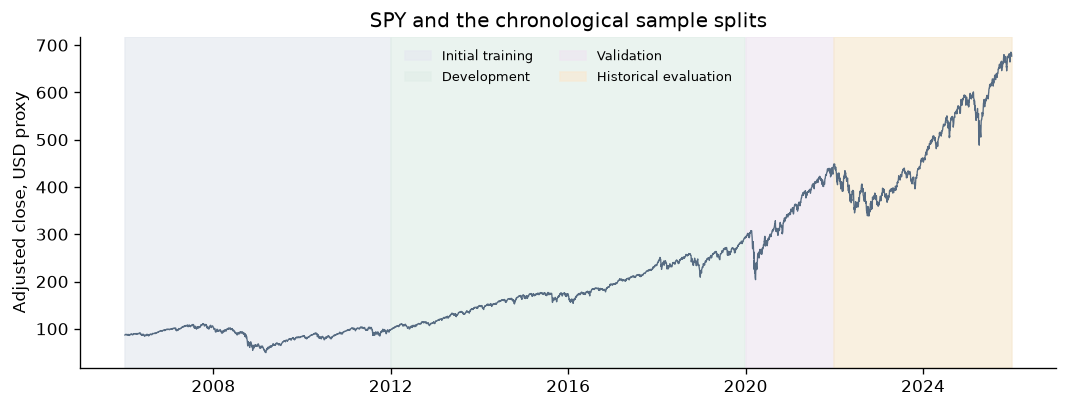

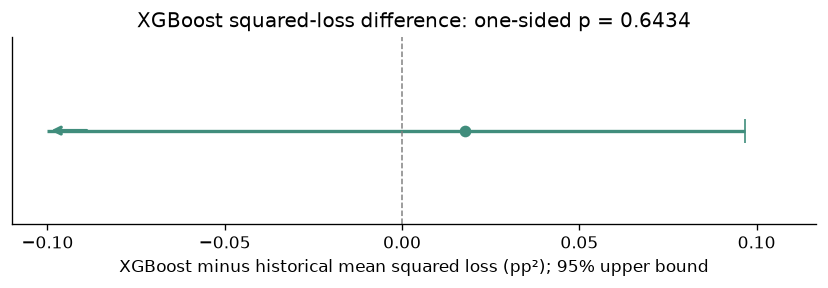

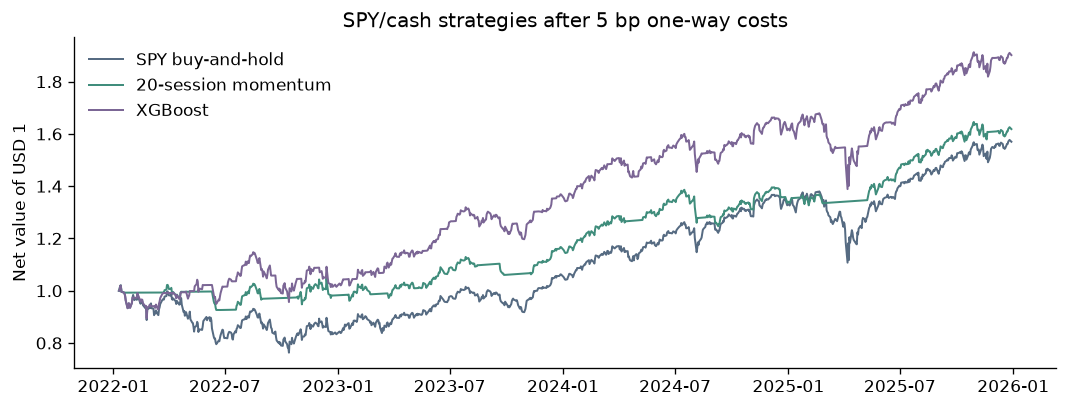

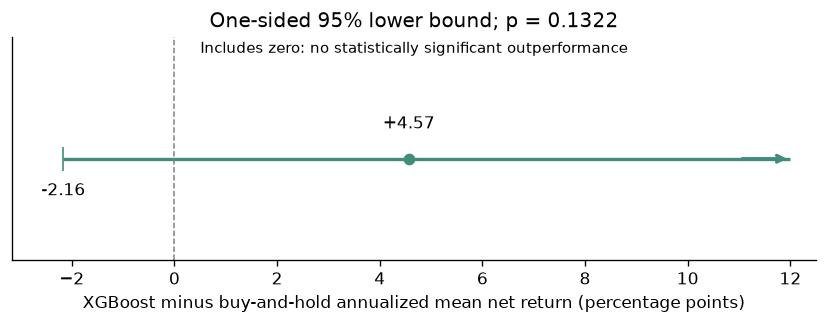

In [6]:
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':160,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
fig,ax=plt.subplots(figsize=(9,3.5))
s=frames['SPY'].adjclose;ax.plot(s.index,s,color='#566b82',lw=.8)
for start,end,color,label in [('2006-01-01','2011-12-31','#e6eaf0','Initial training'),
 ('2012-01-01','2019-12-31','#e2eee9','Development'),('2020-01-01','2021-12-31','#eee7f1','Validation'),
 ('2022-01-01','2025-12-31','#f7ead4','Historical evaluation')]:
    ax.axvspan(pd.Timestamp(start),pd.Timestamp(end),color=color,alpha=.7,label=label)
ax.set(title='SPY and the chronological sample splits',ylabel='Adjusted close, USD proxy')
ax.legend(frameon=False,fontsize=8,ncol=2);fig.tight_layout();fig.savefig(ROOT/'figures/data_splits.png');plt.show()

fig,ax=plt.subplots(figsize=(7,2.5))
center=inference['mean_difference']*10000;upper=inference['upper_95']*10000
left=-.10
ax.hlines(0,left,upper,color='#408d7c',lw=2)
ax.plot(upper,0,marker='|',color='#408d7c',markersize=14)
ax.annotate('',xy=(left,0),xytext=(left+.012,0),arrowprops={'arrowstyle':'->','color':'#408d7c','lw':2})
ax.scatter([center],[0],color='#408d7c',zorder=3)
ax.axvline(0,color='grey',ls='--',lw=.9)
ax.set(yticks=[],ylim=(-.7,.7),xlim=(left-.01,upper+.02),
       title=f"XGBoost squared-loss difference: one-sided p = {inference['p_one_sided']:.4f}",
       xlabel='XGBoost minus historical mean squared loss (pp²); 95% upper bound')
fig.tight_layout();fig.savefig(ROOT/'figures/forecasts.png');plt.show()

fig,ax=plt.subplots(figsize=(9,3.5))
for name,label,color in [('BuyHold','SPY buy-and-hold','#566b82'),('Momentum20','20-session momentum','#408d7c'),('Forecast','XGBoost','#7b6695')]:
    g=ledger[ledger.strategy==name]
    ax.plot(pd.DatetimeIndex([g.entry_date.iloc[0],*g.date]),np.r_[1,g.wealth],label=label,color=color,lw=1.2)
ax.set(title='SPY/cash strategies after 5 bp one-way costs',ylabel='Net value of USD 1')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(ROOT/'figures/trading.png');plt.show()

fig,ax=plt.subplots(figsize=(7,2.8))
estimate=trading_inference['annualized_mean_difference']*100
lower=trading_inference['annualized_lower_95']*100;right=12
ax.hlines(0,lower,right,color='#408d7c',lw=2)
ax.plot(lower,0,marker='|',color='#408d7c',markersize=14)
ax.annotate('',xy=(right,0),xytext=(right-1,0),arrowprops={'arrowstyle':'->','color':'#408d7c','lw':2})
ax.scatter([estimate],[0],color='#408d7c',zorder=3)
ax.axvline(0,color='grey',ls='--',lw=.9)
ax.text(lower,-.18,f'{lower:+.2f}',ha='center');ax.text(estimate,.15,f'{estimate:+.2f}',ha='center')
ax.set(yticks=[],ylim=(-.5,.6),xlim=(lower-1,right+.5),
       title=f"One-sided 95% lower bound; p = {trading_inference['p_one_sided']:.4f}",
       xlabel='XGBoost minus buy-and-hold annualized mean net return (percentage points)')
ax.text(.5,.93,'Includes zero: no statistically significant outperformance',transform=ax.transAxes,ha='center',fontsize=9)
fig.tight_layout();fig.savefig(ROOT/'figures/trading_confidence_bound.png');plt.show()

## Conclusions and limitations

All fixed-configuration fits exactly reproduce the saved forecasts. Forecasting
RMSE is about 2.372 percentage points versus 2.368 for the mean; its one-sided
p-value is 0.6434. The XGBoost strategy earns 17.68% annualized versus 12.10% for
buy-and-hold and 12.97% for momentum, with trading p=0.1322. Neither superiority
claim is supported at 5%.

The evaluation dates were historically examined, and inference choices are
retrospective. Revised vendor prices, assumed execution/costs/cash rates, overlapping
targets, fixed model choices, nonstationarity and few independent market regimes
limit inference. Historical outperformance does not imply causality or reliable
future profitability. All statistical conclusions remain conditional on this rule.